In [5]:
# My CA1 in Data Exploration and Preparation

In [47]:
# Start importing libraries (they store the specific functions we will need)
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("Smart_Home_Energy.csv")

df.head()

,dwelling_type,heating_type,tariff_type,occupants,floor_area_m2,avg_outdoor_temp_c,avg_daily_use_kwh,monthly_bill_eur
0,Semi-detached,Heat Pump,Standard,2,173.7,5.4,18.84,176.72
1,Detached,Gas,Smart,1,131.8,11.1,9.95,96.82
2,Semi-detached,Electric,Smart,4,146.5,12.6,19.54,239.75
3,Semi-detached,Oil,Smart,6,72.4,11.7,14.34,139.45
4,Semi-detached,Heat Pump,Smart,3,170.2,9.2,14.73,148.39


In [48]:
# Understand the dataset
print("Number of observations:", df.shape[0]) # observations = rows
print("Number of variables:", df.shape[1]) # variables = columns

# Dimensions 
print("Dimensions:", df.shape) # observations and variables 

# Finding the variables/columns names 
print("Column names:")
print(df.columns.tolist())


Number of observations: 5507
Number of variables: 8
Dimensions: (5507, 8)
Column names:
['dwelling_type', 'heating_type', 'tariff_type', 'occupants', 'floor_area_m2', 'avg_outdoor_temp_c', 'avg_daily_use_kwh', 'monthly_bill_eur']


In [49]:
# Detailed information of the dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5507 entries, 0 to 5506
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   dwelling_type       5507 non-null   str    
 1   heating_type        5462 non-null   str    
 2   tariff_type         5416 non-null   str    
 3   occupants           5507 non-null   int64  
 4   floor_area_m2       5388 non-null   float64
 5   avg_outdoor_temp_c  5373 non-null   float64
 6   avg_daily_use_kwh   5450 non-null   float64
 7   monthly_bill_eur    5441 non-null   float64
dtypes: float64(4), int64(1), str(3)
memory usage: 467.0 KB


In [50]:
# Details of statistics of the dataset
df.describe()

,occupants,floor_area_m2,avg_outdoor_temp_c,avg_daily_use_kwh,monthly_bill_eur
count,5507.000000,5388.000000,5373.000000,5450.000000,5441.000000
mean,3.617941,126.094321,10.292779,19.389418,196.922007
std,1.859492,78.360763,5.432457,16.425565,190.919214
min,1.000000,30.300000,-27.900000,5.000000,40.000000
25%,2.000000,86.800000,7.100000,13.490000,122.600000
50%,4.000000,116.200000,10.300000,17.370000,169.050000
75%,5.000000,151.700000,13.500000,21.280000,228.820000
max,20.000000,946.700000,46.000000,219.420000,2788.410000


In [51]:
# Find the data types
print("\nData types:")
print(df.dtypes)


Data types:
dwelling_type             str
heating_type              str
tariff_type               str
occupants               int64
floor_area_m2         float64
avg_outdoor_temp_c    float64
avg_daily_use_kwh     float64
monthly_bill_eur      float64
dtype: object


In [52]:
# Finding duplicated values
print(df.duplicated().sum())

157


In [53]:
# Finding missing values 
df.isnull().sum()

dwelling_type           0
heating_type           45
tariff_type            91
occupants               0
floor_area_m2         119
avg_outdoor_temp_c    134
avg_daily_use_kwh      57
monthly_bill_eur       66
dtype: int64

In [54]:
# Remove duplicates creating a copy and not changing the original file
df_analysis = df.drop_duplicates().copy()

In [55]:
# Check the original number of rows and after removing the duplicates
print("Original number of rows:", len(df))
print("Rows after removing duplicates:", len(df_analysis))

Original number of rows: 5507
Rows after removing duplicates: 5350


In [56]:
# Specifying categorical or numerical variables
categorical_columns = ["dwelling_type", "heating_type", "tariff_type"] 
numerical_columns = ["occupants", "floor_area_m2", "avg_outdoor_temp_c", "avg_daily_use_kwh", "monthly_bill_eur"]
print("\nCategorical variables:") 
print(categorical_columns)
print("\nNumerical variables:")
print(numerical_columns)


Categorical variables:
['dwelling_type', 'heating_type', 'tariff_type']

Numerical variables:
['occupants', 'floor_area_m2', 'avg_outdoor_temp_c', 'avg_daily_use_kwh', 'monthly_bill_eur']


In [57]:
# Replace missing values in categorical columns with mode 
categorical_columns = df.select_dtypes(include = ["object", "str"]).columns

for column in categorical_columns:
    df[column] = df[column].fillna(
        df[column].mode()[0]
    )

# Check if missing values have been filled
print(df.isnull().sum())


dwelling_type           0
heating_type            0
tariff_type             0
occupants               0
floor_area_m2         119
avg_outdoor_temp_c    134
avg_daily_use_kwh      57
monthly_bill_eur       66
dtype: int64


In [58]:
# Finding the frequency of categorical values 

print("\nDwelling Type:")
print(df_analysis["dwelling_type"].value_counts())
print("\nHeating Type:")
print(df_analysis["heating_type"].value_counts())
print("\nTariff Type:")
print(df_analysis["tariff_type"].value_counts())



Dwelling Type:
dwelling_type
Semi-detached    1587
Detached         1283
Terraced         1253
Apartment        1182
Semi Detached      45
Name: count, dtype: int64

Heating Type:
heating_type
Gas          2195
Heat Pump    1526
Electric      817
Oil           767
Name: count, dtype: int64

Tariff Type:
tariff_type
Standard       2398
Smart          1843
Night Saver     978
smart            41
Name: count, dtype: int64


In [65]:
# Checking unique categories
print("Dwelling Type Categories:")
print(df['dwelling_type'].unique())
print("Heating Type Categories:")
print(df['heating_type'].unique())
print("Tariff Type Categories:")
print(df['tariff_type'].unique())

Dwelling Type Categories:
<ArrowStringArray>
['Semi-detached', 'Detached', 'Terraced', 'Apartment', 'Semi Detached']
Length: 5, dtype: str
Heating Type Categories:
<ArrowStringArray>
['Heat Pump', 'Gas', 'Electric', 'Oil']
Length: 4, dtype: str
Tariff Type Categories:
<ArrowStringArray>
['Standard', 'Smart', 'Night Saver']
Length: 3, dtype: str


In [68]:
# Fixing typos for the same category
df_analysis["tariff_type"] = df["tariff_type"].replace('smart', 'Smart')

# Checking if it has been fixed accordingly
print("\nTariff Type:")
print(df_analysis["tariff_type"].value_counts())


Tariff Type:
tariff_type
Standard       2488
Smart          1884
Night Saver     978
Name: count, dtype: int64


In [69]:
# Replace missing numerical values 

df["floor_area_m2"] = df["floor_area_m2"].fillna(
    df["floor_area_m2"].mean()
)

df["avg_outdoor_temp_c"] = df["avg_outdoor_temp_c"].fillna(
    df["avg_outdoor_temp_c"].mean()
)

df["avg_daily_use_kwh"] = df["avg_daily_use_kwh"].fillna(
    df["avg_daily_use_kwh"].mean()
)

df["monthly_bill_eur"] = df["monthly_bill_eur"].fillna(
    df["monthly_bill_eur"].mean()
)

# Check if missing values have been filled
print(df.isnull().sum())


dwelling_type         0
heating_type          0
tariff_type           0
occupants             0
floor_area_m2         0
avg_outdoor_temp_c    0
avg_daily_use_kwh     0
monthly_bill_eur      0
dtype: int64


In [70]:
# Detailed descriptive statistics (rounding to get a smaller number and easier to visualize)

print("\nDescriptive Statistics:")

df_analysis[numerical_columns].describe().round(2)


Descriptive Statistics:


,occupants,floor_area_m2,avg_outdoor_temp_c,avg_daily_use_kwh,monthly_bill_eur
count,5350.00,5235.00,5221.00,5296.00,5286.00
mean,3.62,125.82,10.30,19.40,197.63
std,1.86,76.88,5.45,16.43,192.86
min,1.00,30.30,-27.90,5.00,40.00
25%,2.00,87.05,7.10,13.52,122.78
50%,4.00,116.20,10.30,17.39,169.48
75%,5.00,151.50,13.50,21.29,229.38
max,20.00,946.70,46.00,219.42,2788.41


In [71]:
# Calculate averages of numerical values

average_occupants = df_analysis["occupants"].mean()
average_floor_area_m2 = ( df_analysis["floor_area_m2"].mean() )
average_avg_outdoor_temp_c = ( df_analysis["avg_outdoor_temp_c"].mean() )
average_avg_daily_use_kwh = ( df_analysis["avg_daily_use_kwh"].mean() )
average_monthly_bill_eur = ( df_analysis["monthly_bill_eur"].mean() )

print("Average Occupants:", round(average_occupants, 2))
print("Average Floor Area M2:", round(average_floor_area_m2, 2))
print("Average Outdoor Temp C:", round(average_avg_outdoor_temp_c, 2))
print("Average Daily Use kWh:", round(average_avg_daily_use_kwh, 2))
print("Average Monthly Bill Eur:", round(average_monthly_bill_eur,  2))


Average Occupants: 3.62
Average Floor Area M2: 125.82
Average Outdoor Temp C: 10.3
Average Daily Use kWh: 19.4
Average Monthly Bill Eur: 197.63


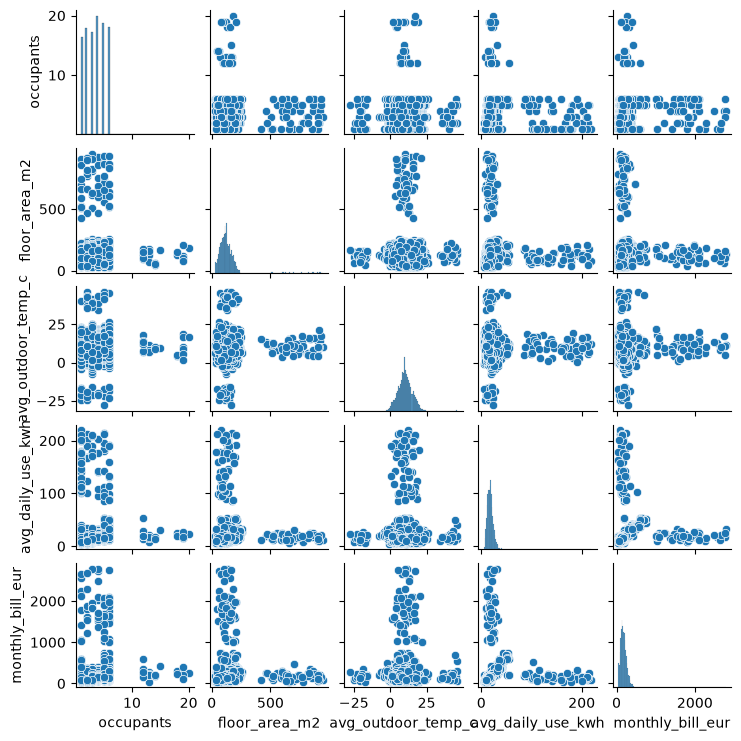

In [72]:
import seaborn as sns
# Create a pairplot for the numerical variables

sns.pairplot(
    df, 
    vars = ["occupants", "floor_area_m2", "avg_outdoor_temp_c", "avg_daily_use_kwh", "monthly_bill_eur"], height = 1.5
)

plt.show()

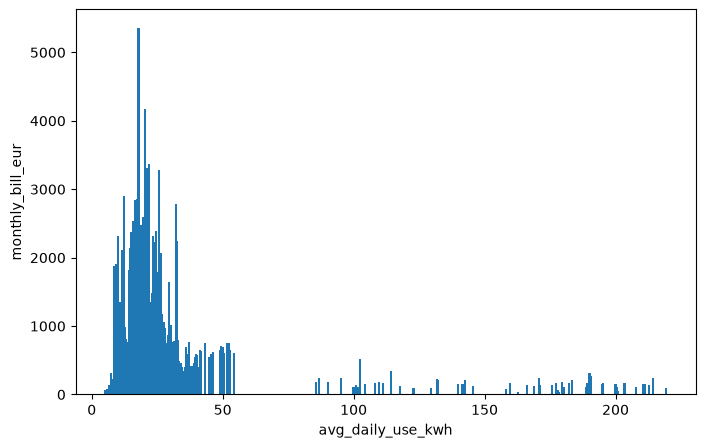

In [78]:
# Bar Chart -  Average Daily Use kWh and Monthly Bill 

average_daily_use_and_bill = df_analysis.groupby("avg_daily_use_kwh")["monthly_bill_eur"].sum()

# Creating a bar chart
plt.figure(figsize = (8, 5))
plt.bar(average_daily_use_and_bill.index, average_daily_use_and_bill.values)

# Add title and labels
plt.xlabel("avg_daily_use_kwh")
plt.ylabel("monthly_bill_eur")


# Display the chart
plt.show()

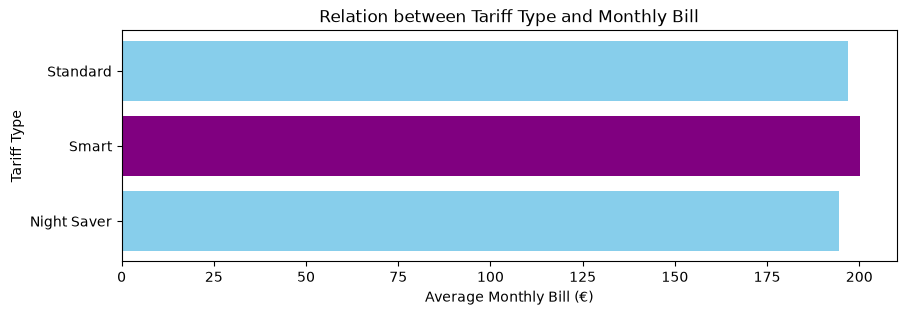

In [100]:
# Plot - Comparing Tariff Type and Monthly Bill

tariff_and_bill = df_analysis.groupby("tariff_type")["monthly_bill_eur"].mean()

# Creating a horizontal bar chart
plt.figure(figsize=(10, 3))

plt.barh(
    tariff_and_bill.index,
    tariff_and_bill.values,
    color=["skyblue", "purple"]
)

# Add title and labels
plt.title("Relation between Tariff Type and Monthly Bill")
plt.xlabel("Average Monthly Bill (€)")
plt.ylabel("Tariff Type")

# Display the chart
plt.show()
